In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Make plots readable
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


## Load the data

In [2]:
from google.colab import files

uploaded = files.upload()  # Select titanic.csv


Saving Titanic-Dataset.csv to Titanic-Dataset.csv


In [3]:
# Read the uploaded CSV file
df = pd.read_csv("Titanic-Dataset.csv")

print("Dataset loaded successfully!")


Dataset loaded successfully!


## Let's go through the data

In [4]:
display(df.head())


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
print("Number of rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())


Number of rows and columns: (891, 12)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [6]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [7]:
# Summary statistics for numerical columns
df.describe()


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
# Summary of categorical columns
df.describe(include="object")


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,347082,G6,S
freq,1,577,7,4,644


## Check the Data quality

In [9]:
# Count missing values in each column
missing_count = df.isnull().sum()
missing_percent = (df.isnull().mean() * 100).round(1)

missing_summary = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_percent
}).sort_values("missing_percent", ascending=False)

display(missing_summary)


,missing_count,missing_percent
Cabin,687,77.1
Age,177,19.9
Embarked,2,0.2
PassengerId,0,0.0
Name,0,0.0
Pclass,0,0.0
Survived,0,0.0
Sex,0,0.0
Parch,0,0.0
SibSp,0,0.0


In [10]:
# Count duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())


Number of duplicate rows: 0


In [12]:
# Inspect some rows where age is missing
df[df["Age"].isna()].head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
17,18,1,2,"Williams, Mr. Charles Eugene",male,NaN,0,0,244373,13.0000,NaN,S
19,20,1,3,"Masselmani, Mrs. Fatima",female,NaN,0,0,2649,7.2250,NaN,C
26,27,0,3,"Emir, Mr. Farred Chehab",male,NaN,0,0,2631,7.2250,NaN,C
28,29,1,3,"O'Dwyer, Miss. Ellen ""Nellie""",female,NaN,0,0,330959,7.8792,NaN,Q


### Which column has the largest number of missing values?

## Univariate analysis:

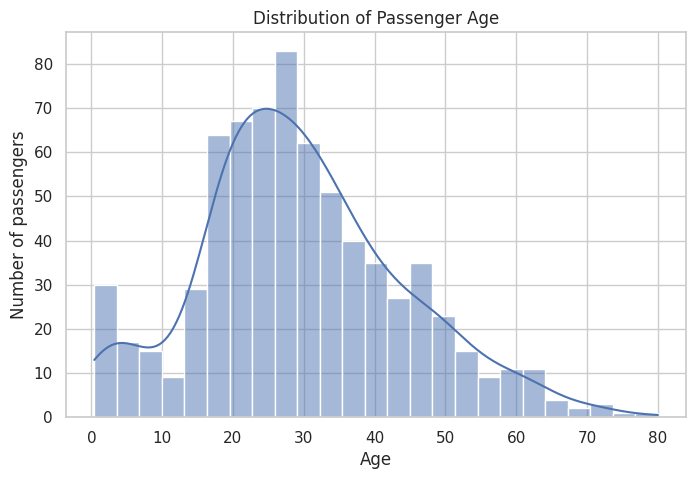

In [14]:
sns.histplot(data=df, x="Age", bins=25, kde=True)
plt.title("Distribution of Passenger Age")
plt.xlabel("Age")
plt.ylabel("Number of passengers")
plt.show()


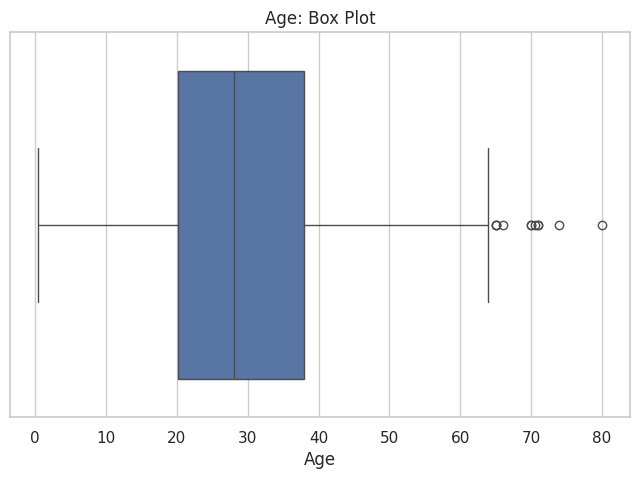

In [15]:
# Box plot: useful for viewing spread and potential outliers
sns.boxplot(data=df, x="Age")
plt.title("Age: Box Plot")
plt.xlabel("Age")
plt.show()


## Categorical Variable

,count
Pclass,
1,216
2,184
3,491


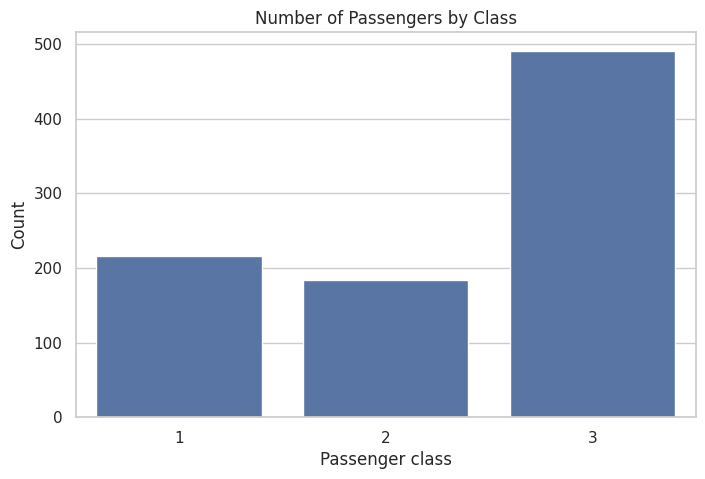

In [18]:
class_counts = df["Pclass"].value_counts().sort_index()
display(class_counts)

sns.countplot(data=df, x="Pclass", order=[1, 2, 3])
plt.title("Number of Passengers by Class")
plt.xlabel("Passenger class")
plt.ylabel("Count")
plt.show()


## Try yourself

1. Plot the distribution of passenger fares.
2. Create a count plot for sex.
3. Which embarkation port has the most passengers?

## Bivariate analysis

In [20]:
#Does survival vary by passenger class?
survival_by_class = pd.crosstab(df["Pclass"], df["Survived"], normalize="index") * 100
survival_by_class.columns = ["Did not survive (%)", "Survived (%)"]
display(survival_by_class.round(1))


,Did not survive (%),Survived (%)
Pclass,,
1,37.0,63.0
2,52.7,47.3
3,75.8,24.2


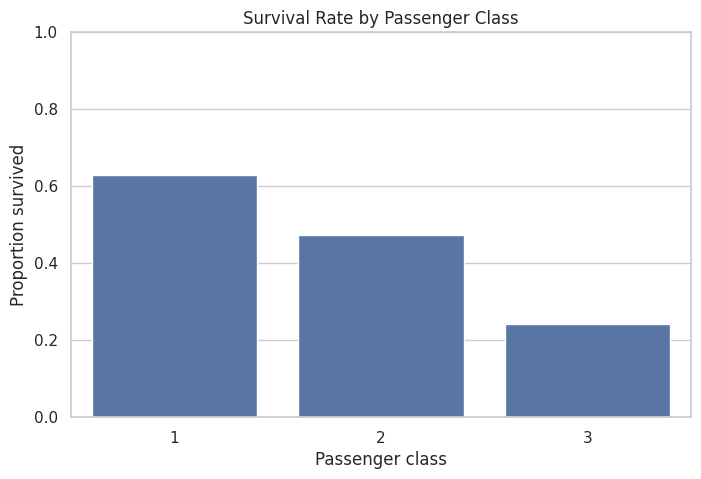

In [22]:
sns.barplot(data=df, x="Pclass", y="Survived", errorbar=None)
plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger class")
plt.ylabel("Proportion survived")
plt.ylim(0, 1)
plt.show()


### Does survival differ by sex?

,Survived
Sex,
female,74.2
male,18.9


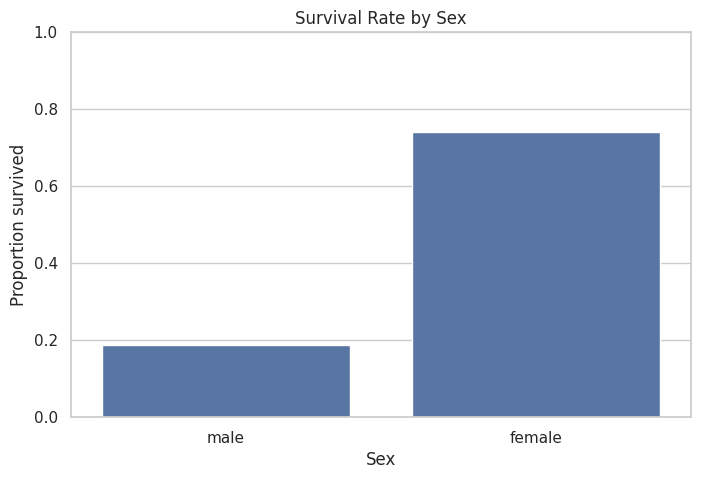

In [25]:
survival_by_sex = df.groupby("Sex", observed=False)["Survived"].mean() * 100
display(survival_by_sex.round(1))

sns.barplot(data=df, x="Sex", y="Survived", errorbar=None)
plt.title("Survival Rate by Sex")
plt.xlabel("Sex")
plt.ylabel("Proportion survived")
plt.ylim(0, 1)
plt.show()


### Is age related to fare?

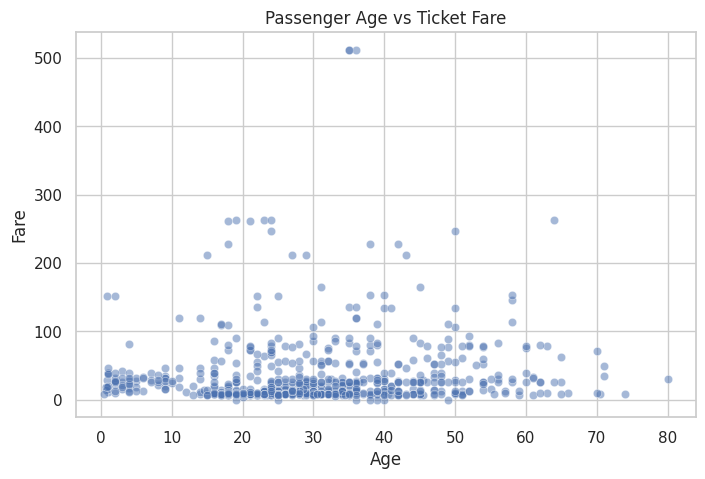

In [26]:
sns.scatterplot(data=df, x="Age", y="Fare", alpha=0.5)
plt.title("Passenger Age vs Ticket Fare")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.show()


## Try yourself

1. Compare the distribution of fares across passenger classes using a box plot.


## Multivariate analysis

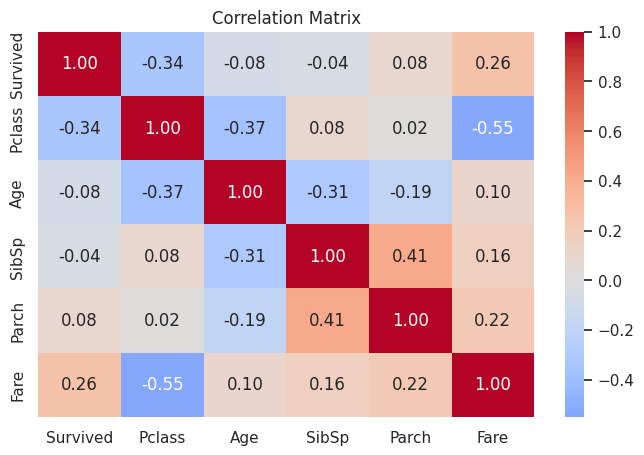

In [28]:
numeric_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
correlation = df[numeric_cols].corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Matrix")
plt.show()


## Try yourself

1. Compare survival across class and sex

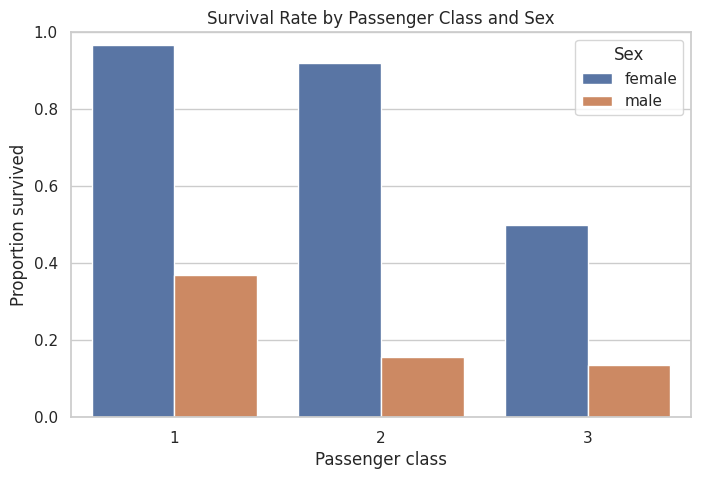

In [29]:
sns.barplot(data=df, x="Pclass", y="Survived", hue="Sex", errorbar=None)
plt.title("Survival Rate by Passenger Class and Sex")
plt.xlabel("Passenger class")
plt.ylabel("Proportion survived")
plt.ylim(0, 1)
plt.show()
